In [4]:
%reload_ext autoreload
%autoreload 2

import os
import sys
sys.path.append('../')
from pathlib import Path
import re
import numpy as np
from scipy.io import loadmat
import pandas as pd
import matplotlib.pyplot as plt

# my inference model modules
from latentEnthalpyModel import latentEnthalpyModel, BasalEvidence, PosteriorConfig
from Simulation import Simulation
from lowRankGPPrior import lowRankGPPrior
from GMMPrior import GMMPrior
from enthalpyPosterior import enthalpyPosterior
from posteriorObjective import posteriorObjective


# Part 1: Load data

Here we load the simulation data, grid, basal thermal evidence (as masks), and create the extent list for visualizing 2D data

In [5]:
data_path = "../data/"

# load simulations, grid, evidence masks, and pressure melting point
grid          = np.load(data_path + "grid.npz")
simulations   = np.load(data_path + "simulations.npz")
evidence_mask = np.load(data_path + "evidence_masks.npz")
pmp           = np.load(data_path + "pmp.npz")["pmp"]

# grid extent
extent_m  = [grid["x"].min(), grid["x"].max(), grid["y"].min(), grid["y"].max()]
extent_km = [x / 1e3 for x in extent_m]



# Part 2: standardization of simulation data

Show the min, max, and the max-min difference diagnostic

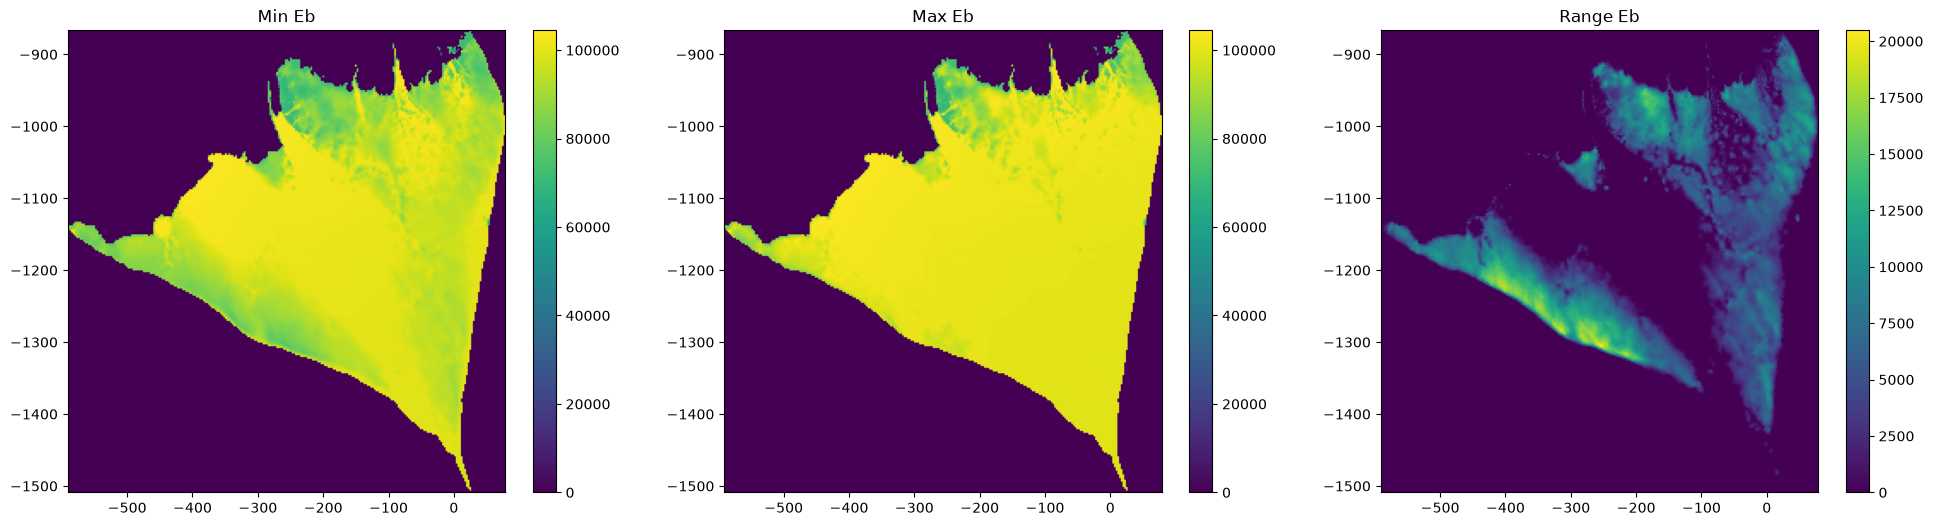

In [6]:
# show the min and max of simulation Eb
min_Eb = np.min(simulations["Eb"], axis = 0)
max_Eb = np.max(simulations["Eb"], axis = 0)

plt.figure(figsize=(24, 6))
plt.subplot(1, 3, 1)
plt.imshow(min_Eb, aspect='auto', origin='lower', extent=extent_km)
plt.title("Min Eb")
plt.colorbar()

plt.subplot(1, 3, 2)
plt.imshow(max_Eb, aspect='auto', origin='lower', extent=extent_km)
plt.title("Max Eb")
plt.colorbar()

plt.subplot(1, 3, 3)
plt.imshow(max_Eb - min_Eb, aspect='auto', origin='lower', extent=extent_km)
plt.title("Range Eb")
plt.colorbar()

plt.show()

/home/donglaiyang/Documents/Georgia-Tech/Research/GMR-inference/src/Simulation.py:127: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


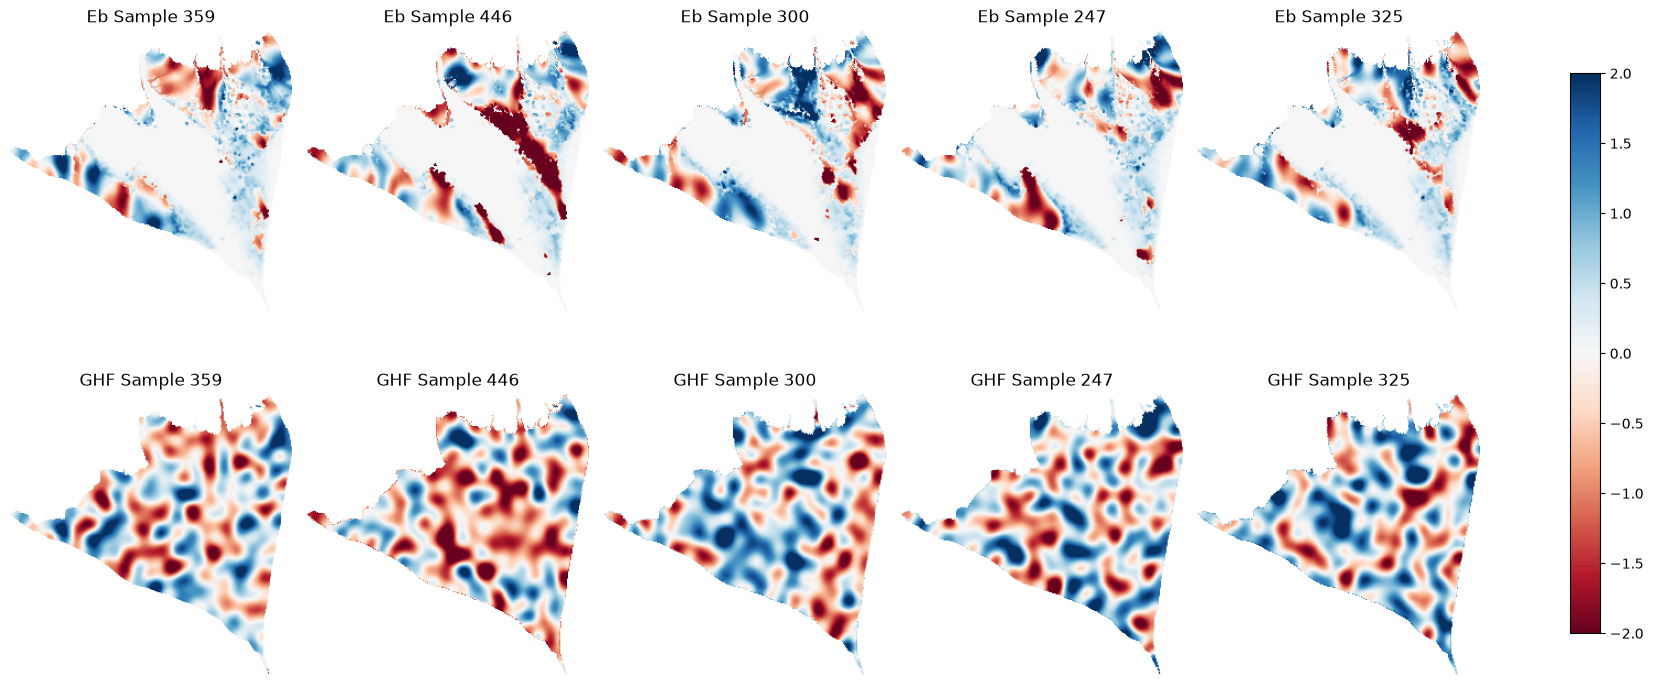

In [9]:
sims = Simulation(
    extent = extent_m,
    coord  = [grid["x"], grid["y"]]
)

sims.load_sim_data(
    X = [simulations["Eb"], simulations["GHF"]],
    labels = ["Eb", "GHF"],
    domain_mask = grid["mask"]
)

sims.show_data(n_samples_to_plot=5)


# Part 3: Density estimation on reduced-dimension simulation data

Find latent representation and tranformation via PAC and apply Gaussian Mixture Model 

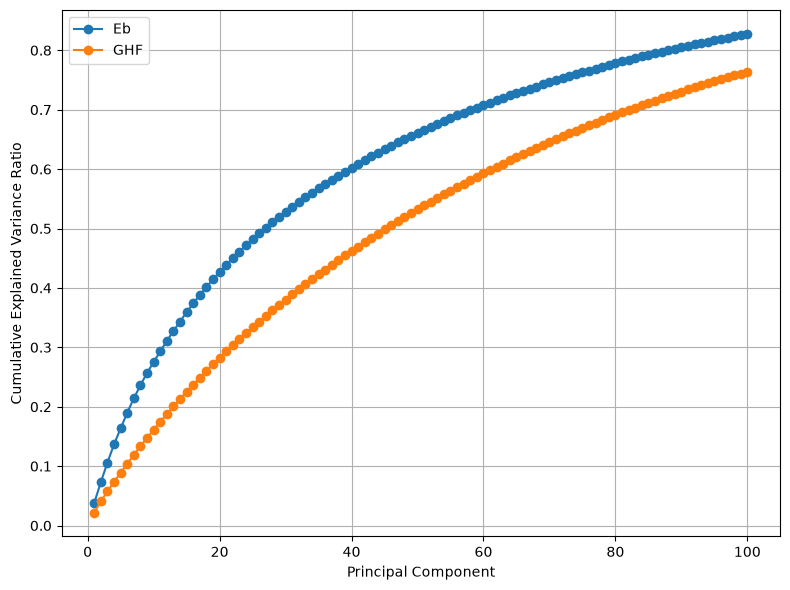

In [10]:
latent_spaces = [100, 100]

sims.find_reduction_model_pca(
    n_latent = latent_spaces,
    show_scree=True)

In [11]:
# split the data into training, validation, and test sets
sims.split_data(train_ratio=0.8, validation_ratio=0.1, test_ratio=0.1)

gmm_n_gaussians = [3, 3]
sims.gmm_prior(n_gaussians = gmm_n_gaussians)

Splitting data: Total samples = 500
-------- Field 0: 
    Shape of X_train[0]: (400, 100)
    Shape of X_validation[0]: (50, 100)
    Shape of X_test[0]: (50, 100)
-------- Field 1: 
    Shape of X_train[1]: (400, 100)
    Shape of X_validation[1]: (50, 100)
    Shape of X_test[1]: (50, 100)
-----------------------------
-----------------------------
Fitting GMMs for each field
--------- Field 0, number of Gaussians: 3
--------- Field 1, number of Gaussians: 3


# Part 4: Creating a mixed prior, likelihood

In [12]:
# prior distributions
gp_prior = lowRankGPPrior(
    domain_mask = sims.domain_mask,
    hx = sims.delta_x,
    hy = sims.delta_y,
    n_mode = 100,
    pca_basis = sims.pca_x[0].components_.T, # only look at Eb
    sigma_amp = 0.1,
    nu = 0.1,
    rho = 1.0,
)

sim_prior = GMMPrior(
    gmm = sims.gmms[0]
)

# remove pixels that are in conflict
thawed_mask = evidence_mask["thawed_mask"] & ~evidence_mask["conflict_mask"]
frozen_mask = evidence_mask["frozen_mask"] & ~evidence_mask["conflict_mask"]
thawed_frac_area = np.where(thawed_mask, 1, 0)
frozen_frac_area = np.where(frozen_mask, 1, 0)

# likelihood
evidence = BasalEvidence.from_arrays(
    Tpmp = pmp,
    thawed_mask = thawed_mask,
    frozen_mask = frozen_mask,
    dw = thawed_frac_area,
    df = frozen_frac_area,
)

config = PosteriorConfig(
    beta = 0.5,
    beta_w = 0.005
)


Step 1: Eigen-decomposition on graph Laplacian...
...Done.
Step 2: Get mode covariance under Matern kernel...
...Done.
Step 3: Projecting away and performing SVD...
...Done.


# Part 5: Solve for MAP and posterior distributions

In [ ]:
forward_model = latentEnthalpyModel(
    pca = sims.pca_x[0],
    gp = gp_prior,
    Eb_mean = md.X_mean,
    Eb_std  = md.X_std,
    Eb_epsilon = md.X_epsilon,
    method = "relaxation",
    Tpmp = md.pmp,
)

posterior = enthalpyPosterior(
    forward_model = forward_model,
    evidence = evidence,
    gmm = sim_prior,
    gp  = gp_prior,
    config = config,
)

# initialize posterior guess
n_gmm_dim = len(md.x_indices)
n_gp_dim  = gp_prior.n_mode

objective = posteriorObjective(
    posterior = posterior,
)


theta0 = np.concatenate([
    torch.zeros(n_gp_dim),
    torch.zeros(n_gmm_dim)
])

result = sp.optimize.minimize(
    fun = objective.value,
    x0  = theta0,
    jac = objective.gradient,
    method = "L-BFGS-B",
        options={
        # "maxiter": 500,
        # "maxfun": 500,
        "disp": True,
        "ftol": 1e-9,
        "gtol": 1e-6,
        "maxls": 10,
    },
)

### Posterior distributions: Laplace approximation

### Posterior distribution: Hamiltonian Monte Carlo